# HW4: Stock-return model and backtester – Terence Chiu

Predict 90-day returns, trade on the predictions with my own backtester, and compare against `^SP500TR` from $1,000,000 over the final test (2016-04-01 to 2026-09-30).

In [1]:
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

REPO = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
MODELING = REPO / "Lectures" / "modeling"
DB_PATH = MODELING / "data" / "equities_top2000.duckdb"
sys.path.insert(0, str(MODELING))
import course_data  # course-provided loading/preprocessing, reused with citation (see README)

DEV_START, DEV_END = "2010-01-01", "2015-12-31"
TEST_START, TEST_END = "2016-04-01", "2026-09-30"
INITIAL_CAPITAL = 1_000_000
RISK_FREE = 0.02

## 1. Data panel

- [ ] Build the panel once for the full period with `course_data.prepare_panel(database=DB_PATH, end=TEST_END)`
- [ ] Inspect `.shape`, `.columns`, `.head()`, and the label distribution
- [ ] Split by date into development and test rows (keep the Q1 2016 buffer out of both)

In [2]:
raw = course_data.prepare_panel(database=DB_PATH, end=TEST_END)
print("Shape: ", raw.shape)
print("Columns: ", raw.columns)
print("Head: ", raw.head())

/Users/terencechiu/Developer/Berkeley/UCB-MFE-python-preprogram-2026-winter/Lectures/modeling/course_data.py:204: UserWarning: Quarantining 275 invalid adjusted-price rows; inspect the raw database and delivery audit.
  prices, fundamentals, universe, benchmark = load_data(database, end=end)
/Users/terencechiu/Developer/Berkeley/UCB-MFE-python-preprogram-2026-winter/Lectures/modeling/course_data.py:204: UserWarning: Quarantining 28 price rows outside the supplied market calendar; inspect the raw database and delivery audit.
  prices, fundamentals, universe, benchmark = load_data(database, end=end)


Shape:  (15839485, 33)
Columns:  Index(['date', 'symbol', 'close', 'adj_close', 'volume', 'momentum_21',
       'momentum_63', 'momentum_252_21', 'volatility_63', 'drawdown_252',
       'eligible', 'fiscal_date', 'filing_date', 'available_date',
       'net_margin', 'operating_roa', 'debt_to_assets', 'cash_to_assets',
       'fcf_to_assets', 'accruals_to_assets', 'filing_age_days', 'sector',
       'membership_quarter', 'quarter_end', 'universe_selection_date',
       'universe_rank', 'is_universe_member', 'entry_date', 'entry_price',
       'scheduled_exit', 'label_end', 'exit_price', 'target'],
      dtype='object')
Head:          date symbol      close  adj_close       volume  momentum_21  \
0 2000-01-03      A   48.51000  40.300000    4962189.0          NaN   
1 2000-01-03     AA   91.02000  63.110000    1379436.0          NaN   
2 2000-01-03   AAIC  142.50000  24.392216       2770.0          NaN   
3 2000-01-03   AAON    0.79014   0.651150    1026865.0          NaN   
4 2000-01-03

In [3]:
raw.eligible.sum()

np.int64(12117367)

In [4]:
raw.loc[raw.eligible, "target"].describe()

count    1.195694e+07
mean     1.559475e-01
std      1.085582e+02
min     -9.999923e-01
25%     -7.831809e-02
50%      2.442748e-02
75%      1.293508e-01
max      1.427073e+05
Name: target, dtype: float64

In [5]:
from sklearn.linear_model import Ridge
from sklearn.model_selection import GridSearchCV

panel = raw
development = panel.loc[panel.eligible & panel.date.ge(DEV_START)
                        & panel.date.le(DEV_END) & panel.label_end.lt(TEST_START)].reset_index(drop=True)
folds = course_data.date_folds(development, validation_years=(2012, 2013, 2014))

print(len(development))
print("Date range: ", development.date.min(), "to", development.date.max())
print("targets > +500%:", (development.target > 5).sum())
print(development.target.quantile([0.001, 0.01, 0.5, 0.99, 0.999]))

2967493
Date range:  2010-01-04 00:00:00 to 2015-12-30 00:00:00
targets > +500%: 488
0.001   -0.705620
0.010   -0.450893
0.500    0.026178
0.990    0.651515
0.999    1.761742
Name: target, dtype: float64


## 2. Model

- [ ] One model via `course_data.make_pipeline` (e.g. ridge regression)
- [ ] Chronological validation with `course_data.date_folds`; record the metric (`course_data.prediction_metrics`)
- [ ] Fit the final model on development rows only; never on test rows

In [ ]:
X = development[course_data.FEATURES]
lo, hi = development["target"].quantile([0.01, 0.99])
y = development["target"].clip(lo, hi)

search = GridSearchCV(course_data.make_pipeline(), {"model__alpha": [1, 100, 1000]}, cv=folds, scoring="neg_root_mean_squared_error")
search.fit(X, y)

final_model = search.best_estimator_
final_params = search.best_params_

In [9]:
final_params

{'model__alpha': 1000}

## 3. Backtester (my own implementation)

- [ ] Tracks purchases, sales, cash, open positions, and daily portfolio value
- [ ] Decisions use information available before the fill; entries fill at the close
- [ ] Never spends the same cash twice; states assumptions for costs, missing prices, and cash interest

### Hand check

- [ ] A tiny example (e.g. 2 stocks, a few days) whose cash, positions and daily value I can verify by hand

In [17]:
initial_cash_stock = 1000
days = 5

prices = pd.DataFrame(
    {"AAA": [100, 101, 98, 95, 99], 
    "BBB": [100, 90, 87, 92, 91]},
    index=pd.RangeIndex(days, name="day")
)

expected = pd.DataFrame(
    {
        "cash": [0, 0, 0, 0, 1900],
        "AAA_units": [10, 10, 10, 10, 0],
        "BBB_units": [10, 10, 10, 10, 0],
        "value": [2000, 1910, 1850, 1870, 1900],
    },
    index=pd.RangeIndex(days, name="day")
)

In [18]:
expected

,cash,AAA_units,BBB_units,value
day,,,,
0,0,10,10,2000
1,0,10,10,1910
2,0,10,10,1850
3,0,10,10,1870
4,1900,0,0,1900


In [25]:
%load_ext autoreload 
%autoreload 2
from hw4_backtester import Backtester

FEE_RATE = 0.01
entries = [(0, 4, ["AAA", "BBB"])]

bt = Backtester(prices=prices, entries=entries, initial_cash=initial_cash_stock*2, annual_rf=0, fee_rate=0)
history, trades = bt.run_backtest()

assert np.allclose(history["cash"], expected["cash"])
assert np.allclose(history["value"], expected["value"])

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## 4. Runs

- [ ] Sanity run on development data
- [ ] Final test run **once**, with the strategy fixed beforehand

In [29]:
TOP_N = 20

dates = pd.DatetimeIndex(np.sort(panel.date.unique()))
test_dates = dates[(dates >= TEST_START) & (dates <= TEST_END)]

schedule = []
i = 0

while i < len(test_dates):
    entry = test_dates[i]
    signal_date = dates[dates.get_loc(entry)-1]
    m = test_dates.searchsorted(entry + pd.Timedelta(days=90))
    maturity = test_dates[m] if m < len(test_dates) else pd.Timestamp.max
    schedule.append((signal_date, entry, maturity))
    i = m + 1

signal_dates = [s for s, _, _ in schedule]
rows = panel.loc[panel.eligible & panel.date.isin(signal_dates)].copy()
rows["score"] = final_model.predict(rows[course_data.FEATURES])
top = rows.sort_values("score", ascending=False).groupby("date").head(TOP_N)
picks = top.groupby("date")["symbol"].apply(list).to_dict()

In [31]:
entries = [(entry, maturity, picks[signal]) for signal, entry, maturity in schedule]

symbols = sorted({s for _, _, syms in entries for s in syms})
prices = (panel.loc[panel.date.isin(test_dates) & panel.symbol.isin(symbols)]
          .pivot(index="date", columns="symbol", values="adj_close"))

print(len(entries), "cycles |", len(symbols), "symbols | prices", prices.shape)
for entry, maturity, syms in entries[:3]:
    print(entry.date(), "->", maturity.date(), syms[:5])

43 cycles | 422 symbols | prices (2640, 422)
2016-04-01 -> 2016-06-30 ['BOOT', 'ENTA', 'DOC', 'DECK', 'LXRX']
2016-07-01 -> 2016-09-29 ['FWONK', 'FWONA', 'WINA', 'ENDP', 'HRB']
2016-09-30 -> 2016-12-29 ['TSCO', 'MYGN', 'VIA', 'SPKE', 'IRMD']


In [34]:
history, trades = Backtester(prices=prices, entries=entries, initial_cash=INITIAL_CAPITAL, annual_rf=RISK_FREE).run_backtest()
history = history.set_index("day")
print("Last of history: \n")
display(history.tail())
print("Final value:", round(history.value.iloc[-1], 2))
print("Number of trades: ", len(trades))
print("Most stale posiitons on one day: ", history.n_stale.max())

Last of history: 



,cash,value,n_stale
day,,,
2026-09-24,4.532625e-10,2.254346e+06,4
2026-09-25,4.532985e-10,2.253928e+06,4
2026-09-28,1.982395e+06,2.227336e+06,4
2026-09-29,4.802132e-10,2.226502e+06,4
2026-09-30,4.802513e-10,2.199861e+06,4


Final value: 2199861.34
Number of trades:  1696
Most stale posiitons on one day:  4


## 5. Evaluation vs `^SP500TR`

For both portfolios: final value, CAGR, maximum drawdown, Sharpe (daily returns, 2% risk-free rate).

- [ ] Benchmark: $1,000,000 in `^SP500TR` at the first test close, held to the same end date
- [ ] Both cumulative-return curves on one chart
- [ ] Did I beat the benchmark, and by how much?

In [42]:
import duckdb
with duckdb.connect(str(DB_PATH), read_only=True) as con:
    bench = con.execute(
        "SELECT date, adj_close FROM benchmark "
        "WHERE symbol = '^SP500TR' AND date BETWEEN ? AND ? ORDER BY date",
        [TEST_START, TEST_END],
    ).df()

bench["date"] = pd.to_datetime(bench["date"])
bench = bench.set_index("date")["adj_close"]
benchmark_value = INITIAL_CAPITAL * bench / bench.iloc[0]

In [45]:
def metrics(v):
    years = (v.index[-1] - v.index[0]).days / 365.25
    returns = v.pct_change().dropna()
    excess = returns - ((1 + RISK_FREE) ** (1 / 252) - 1)

    cagr = (v.iloc[-1] / v.iloc[0]) ** (1 / years) - 1
    max_drawdown = v / v.cummax() - 1
    sharpe = excess.mean() / excess.std() * np.sqrt(252)

    return pd.Series({
        "Final Value": v.iloc[-1],
        "CAGR": cagr, 
        "Max Drawdown": max_drawdown.min(),
        "Sharpe Ratio" : sharpe
    })

results = pd.DataFrame({
    "Strategy": metrics(history["value"]),
    "^SP500TR": metrics(benchmark_value),
})
display(results)

,Strategy,^SP500TR
Final Value,2.199861e+06,4.402747e+06
CAGR,7.805105e-02,1.516619e-01
Max Drawdown,-5.206128e-01,-3.379046e-01
Sharpe Ratio,3.341581e-01,7.726897e-01


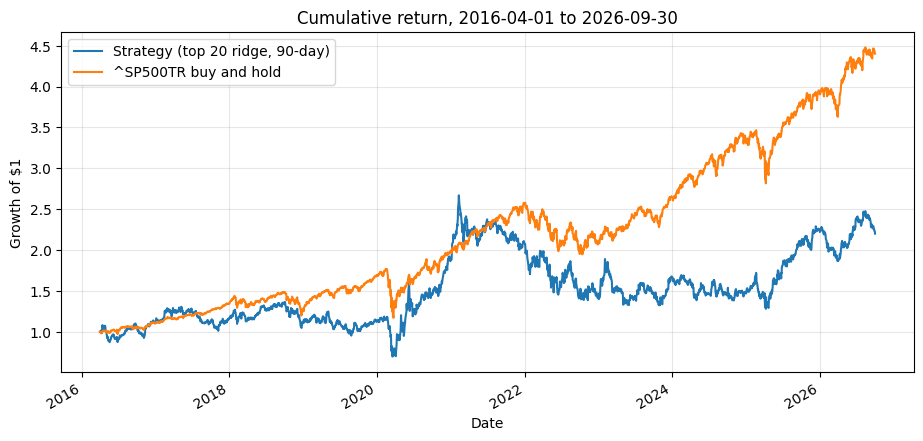

In [46]:
ax = (history["value"] / INITIAL_CAPITAL).plot(label="Strategy (top 20 ridge, 90-day)", figsize=(11, 5))
(benchmark_value / INITIAL_CAPITAL).plot(ax=ax, label="^SP500TR buy and hold")
ax.set(title="Cumulative return, 2016-04-01 to 2026-09-30", ylabel="Growth of $1", xlabel="Date")
ax.grid(alpha=0.3); ax.legend()
plt.savefig("cumulative_returns.png", dpi=150, bbox_inches="tight")
plt.show()

## 6. Findings

The strategy did not beat `^SP500TR`: 7.81% vs 15.17% CAGR, with a deeper maximum drawdown (−52.1% vs −33.8%) and a lower Sharpe ratio (0.33 vs 0.77). It roughly kept pace until early 2021, then lost about half its value while the index kept rising.

- About $245k of the final value sits in 4 stocks that stopped trading, valued at their last price; if they were worthless, the final value would be about $1.95M.
- The signal is weak: ridge chose the strongest penalty tried, and the model was never retrained after 2015.
- The top 20 can include two share classes of one company (FWONK and FWONA).

Full findings, limitations and next steps are in `README.md`.